# 05 · Comparison table, charts and error analysis

Reads `results/metrics.csv`, `results/predictions_test.csv` and `results/predictions_hard.csv`, written by
notebooks 02-04. Run those first; any model that has not been run is simply missing from the tables.

In [1]:
import sys, pathlib
NB_DIR = pathlib.Path.cwd().resolve()
if NB_DIR.name != "notebooks":        # Jupyter was started in the repo root instead of notebooks/
    NB_DIR = NB_DIR / "notebooks"
ROOT = NB_DIR.parent                  # repo root (data/, results/, prompts.md ...)
sys.path.insert(0, str(NB_DIR))       # so "from src import ..." finds notebooks/src/

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

from src import config, data, evaluate as ev
from src.profanity import mask, mask_frame     # curse words are masked in everything shown

LABELS = config.LABELS
TIER_COLORS = {"1 rule-based": "#c98b2b", "2 classic ML": "#4a6fa5", "3 LLM": "#7a4fa3"}

train, test = data.load_split()
hard = data.load_hard_cases()
m = ev.load_metrics().sort_values(["tier", "macro_f1"]).reset_index(drop=True)
preds = pd.read_csv(config.PREDICTIONS_FILE)
hard_preds = pd.read_csv(config.HARD_PREDICTIONS_FILE)
models = list(m["model"])

## 1. Results table

In [2]:
table = pd.DataFrame({
    "Model": m["model"],
    "Tier": m["tier"],
    "Accuracy": m["accuracy"].round(3),
    "Macro-F1": m["macro_f1"].round(3),
    "Hard-cases acc": m["hard_acc"].round(3),
    "Sec / 1k": m["sec_per_1k"].round(2),
    "Cost / 1k (USD)": m["cost_per_1k_usd"].round(4),
})

# the same table as Markdown, ready to paste into README.md and the report
cols = list(table.columns)
md = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
md += ["| " + " | ".join(str(v) for v in row) + " |" for row in table.itertuples(index=False)]
print("\n".join(md))
table

| Model | Tier | Accuracy | Macro-F1 | Hard-cases acc | Sec / 1k | Cost / 1k (USD) |
|---|---|---|---|---|---|---|
| VADER (stock) | 1 rule-based | 0.37 | 0.365 | 0.3 | 0.09 | 0.0 |
| VADER + Taglish lexicon | 1 rule-based | 0.597 | 0.588 | 0.7 | 0.17 | 0.0 |
| NLTK + Naive Bayes | 2 classic ML | 0.68 | 0.637 | 0.567 | 0.14 | 0.0 |
| Claude Haiku 5.5 zero-shot | 3 LLM | 0.81 | 0.797 | 0.9 | 886.6 | 0.0453 |


,Model,Tier,Accuracy,Macro-F1,Hard-cases acc,Sec / 1k,Cost / 1k (USD)
0,VADER (stock),1 rule-based,0.370,0.365,0.300,0.09,0.0000
1,VADER + Taglish lexicon,1 rule-based,0.597,0.588,0.700,0.17,0.0000
2,NLTK + Naive Bayes,2 classic ML,0.680,0.637,0.567,0.14,0.0000
3,Claude Haiku 5.5 zero-shot,3 LLM,0.810,0.797,0.900,886.60,0.0453


## 2. Charts

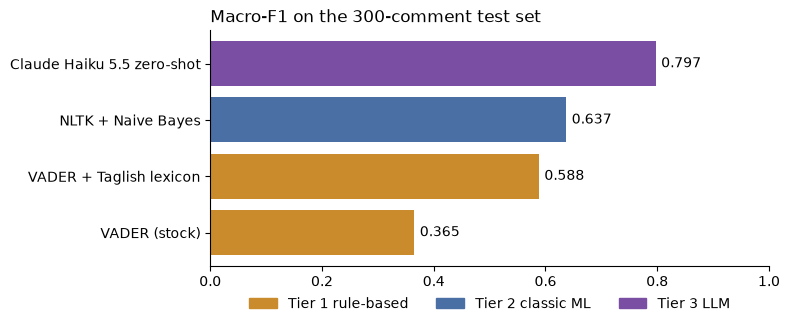

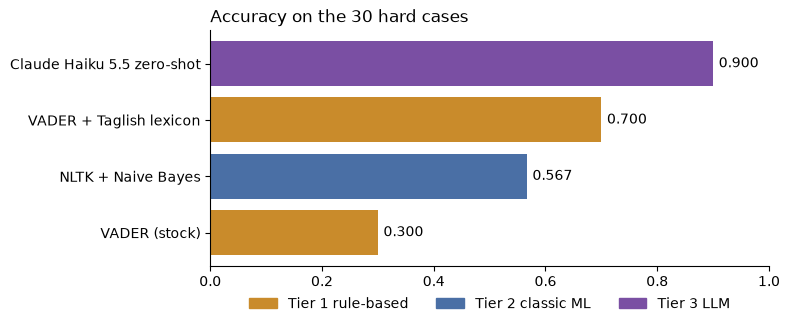

In [3]:
def bar_chart(col, title, fname):
    d = m.sort_values(col)
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(d) + 1.2))
    bars = ax.barh(d["model"], d[col], color=[TIER_COLORS.get(t, "#888") for t in d["tier"]])
    for b, v in zip(bars, d[col]):
        ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
    ax.set_xlim(0, 1)
    ax.set_title(title, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in TIER_COLORS.values()]
    ax.legend(handles, ["Tier " + t for t in TIER_COLORS], loc="upper center",
              bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
    plt.tight_layout()
    plt.savefig(config.CHARTS / fname, dpi=150)
    plt.show()

bar_chart("macro_f1", "Macro-F1 on the 300-comment test set", "macro_f1_by_model.png")
bar_chart("hard_acc", "Accuracy on the 30 hard cases", "hard_cases_accuracy.png")

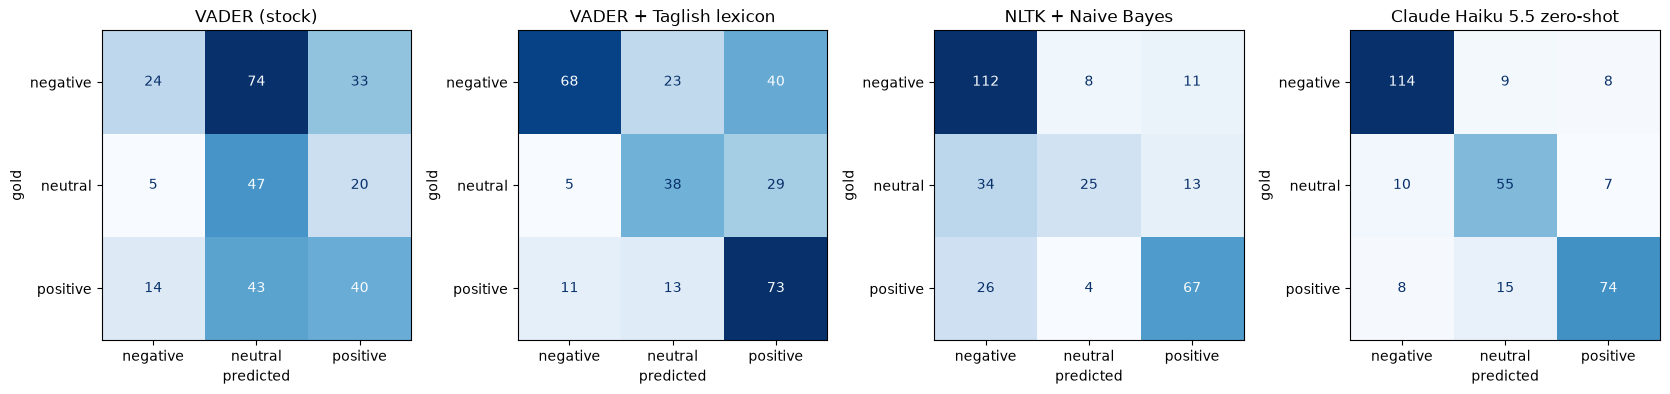

In [4]:
n = len(models)
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4))
axes = [axes] if n == 1 else axes
for ax, name in zip(axes, models):
    ev.plot_confusion(test["label"], preds[name], name, ax=ax, save=False)
plt.tight_layout()
plt.savefig(config.CHARTS / "confusion_matrices_all.png", dpi=150)
plt.show()

## 3. Per-language macro-F1 (test set)

In [5]:
d = test[["label_id", "label", "lang"]].merge(preds, on="label_id")
rows = []
for lang, g in d.groupby("lang"):
    row = {"lang": lang, "n": len(g)}
    for name in models:
        row[name] = f1_score(g["label"], g[name], labels=LABELS, average="macro", zero_division=0)
    rows.append(row)
pd.DataFrame(rows).set_index("lang").round(3)

,n,VADER (stock),VADER + Taglish lexicon,NLTK + Naive Bayes,Claude Haiku 5.5 zero-shot
lang,,,,,
english,18,0.721,0.721,0.630,0.915
tagalog,236,0.321,0.574,0.621,0.774
taglish,22,0.457,0.364,0.700,0.820
unknown,24,0.358,0.650,0.464,0.746


## 4. Hard cases by phenomenon (share correct)

In [6]:
h = hard[["hard_id", "label", "phenomenon"]].merge(hard_preds, on="hard_id")
for name in models:
    h[name] = (h[name] == h["label"]).astype(int)
h.groupby("phenomenon")[models].mean().round(2).assign(n=h.groupby("phenomenon").size())

,VADER (stock),VADER + Taglish lexicon,NLTK + Naive Bayes,Claude Haiku 5.5 zero-shot,n
phenomenon,,,,,
booster,0.33,1.00,0.33,1.0,3
contrast,0.40,1.00,0.80,0.8,5
laughter_only,1.00,0.00,0.00,1.0,1
like_bait,0.00,0.00,0.00,1.0,1
lukewarm,0.00,0.00,0.00,0.0,1
mild_negative,1.00,1.00,1.00,1.0,1
mixed,0.00,0.00,1.00,1.0,1
negation,0.00,0.80,0.60,1.0,5
negation_contrast,0.50,1.00,0.50,1.0,2


## 5. Error analysis

In [7]:
pd.set_option("display.max_colwidth", 120)
d = test[["label_id", "text_clean", "label"]].merge(preds, on="label_id")
d["n_wrong"] = sum((d[name] != d["label"]).astype(int) for name in models)
print("comments every model got wrong:", (d["n_wrong"] == len(models)).sum())
mask_frame(d[d["n_wrong"] == len(models)][["text_clean", "label"] + models].head(15))

comments every model got wrong: 12


,text_clean,label,VADER (stock),VADER + Taglish lexicon,NLTK + Naive Bayes,Claude Haiku 5.5 zero-shot
6,2 n 1 kawawa ni abra XD,neutral,positive,positive,negative,negative
49,Alams na kung bakt malakas mang distract tapos bakit ganyan sila smugg dahil pinag gaganti nila sila krazy mix kase ...,neutral,negative,positive,negative,positive
52,Luto sir,positive,neutral,negative,negative,negative
53,Mga punch lines na binigay ng LA nabalik lahat ng SS,positive,neutral,neutral,negative,neutral
55,Eto ang pinakabagong comment. Oraaaytt,positive,neutral,neutral,negative,neutral
57,S/S? HUH Sori iND NIO DESERVE... L/A ang nanalo. . Ok lang yun L/A Good job.. From PAmpAngA.Peace,negative,positive,positive,positive,positive
59,loonie bawi ka namn idol pinahiya ka idol,negative,neutral,positive,positive,positive
72,k wet dreams pre!! hahaha youAREkolokoy may bestfriend k n d2 ah... ang sweet nyo promise... :)),negative,positive,positive,neutral,neutral
91,Nakakamiss tong battle na to. Hirap kalaban ng mga naka shabu,positive,negative,neutral,negative,neutral
94,Pag ako kahit Talo sila L/A bigyan ko sila 150000 pesos,positive,neutral,negative,negative,neutral


In [8]:
# where the best classic-ML model and the best LLM disagree, who is right?
ml = m[m["tier"] == "2 classic ML"].sort_values("macro_f1").tail(1)["model"].tolist()
llm = m[m["tier"] == "3 LLM"].sort_values("macro_f1").tail(1)["model"].tolist()
if ml and llm:
    a, b = ml[0], llm[0]
    dis = d[d[a] != d[b]]
    print(f"{len(dis)} disagreements | {a} right: {(dis[a] == dis['label']).sum()} | "
          f"{b} right: {(dis[b] == dis['label']).sum()}")
    display(mask_frame(dis[["text_clean", "label", a, b]].head(15)))
else:
    print("Run notebooks 03 and 04 first.")

104 disagreements | NLTK + Naive Bayes right: 24 | Claude Haiku 5.5 zero-shot right: 63


,text_clean,label,NLTK + Naive Bayes,Claude Haiku 5.5 zero-shot
0,corny ibang lines :3 TEAM Loonie/Abra <3 <3 mahal ko kayo,positive,neutral,positive
1,hindi ba luto yun?!!! 7-0??... kakupalan yan,negative,neutral,negative
2,ang serioso nilang Loonie at Abra habang sina Smugglaz at Sheyhee nakakatawa🤣🤣,positive,negative,positive
3,24:05 check nyo ulit.. ahahaha dami ko tlaga tawa..,positive,positive,neutral
4,C******a Na Yan .. C******a Na Yan .. C******a Na Yan ...,neutral,positive,negative
10,sino nannalo,neutral,negative,neutral
11,Sinio vs Sheyee 😂😂😂 is Hart hart,neutral,negative,neutral
14,omaygas 43 minutes to xD WTHH,neutral,negative,neutral
15,Galing nila loonie at abra bakit sila pa na talo mga p**a,negative,positive,negative
20,Oct 12 2026 may nanunuod paba?,neutral,positive,neutral


## 6. Conclusion (fill in after running everything)

- **Best macro-F1:** …
- **Best on hard cases:** …
- **Fastest / cheapest:** …
- **Recommendation:** which tier would you deploy for this comment section, and why?